# Pricing Any Security at Any Horizon in a Finite-State Markov Economy

This notebook prices a state-contingent security in a finite-state Markov consumption economy.

## Inputs

- $\rho$: curvature coefficient in CRRA utility
- $\beta$: subjective discount factor
- $P$: $n\times n$ Markov transition matrix
- $c$: $n\times 1$ vector of consumption levels
- $r$: $n\times 1$ vector of security payoffs at horizon $T$
- $T$: horizon at which the security pays

Preferences are

$$
u(c)=
\begin{cases}
\dfrac{c^{1-\rho}-1}{1-\rho}, & \rho\neq 1,\\[4pt]
\log c, & \rho=1,
\end{cases}
\qquad
u'(c)=c^{-\rho}.
$$

If the current state is $i$ and next period's state is $j$, the stochastic discount factor is

$$
m_{ij}
=
\beta\frac{u'(c_j)}{u'(c_i)}
=
\beta\left(\frac{c_j}{c_i}\right)^{-\rho}.
$$

The one-period pricing matrix is

$$
Q_{ij}=P_{ij}m_{ij}.
$$

A security that pays the vector $r$ exactly $T$ periods from today has price vector

$$
\boxed{p^{(T)}=Q^T r}.
$$

The $i$th element is the security's price when today's Markov state is $i$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)


## 1. Enter the economic environment

The example below has three states. Replace these inputs with any finite-state Markov economy.

The payoff vector `r` gives the security payoff in each state **at date $T$**.


In [2]:
# Preferences
rho = 2.0
beta = 0.97

# Markov transition matrix
P = np.array([
    [0.80, 0.15, 0.05],
    [0.10, 0.80, 0.10],
    [0.05, 0.15, 0.80]
], dtype=float)

# Consumption in each state
c = np.array([0.5, 1.0, 1.5], dtype=float)

# State-contingent payoff of the security at horizon T
r = np.array([1.0, 0.0, 0.0], dtype=float)

# Horizon
T = 5


## 2. Validate the inputs

A valid transition matrix must be square, nonnegative, and have rows that sum to one. Consumption must be strictly positive because CRRA marginal utility is $c^{-\rho}$.


In [3]:
def validate_inputs(rho, beta, P, c, r, T):
    P = np.asarray(P, dtype=float)
    c = np.asarray(c, dtype=float).reshape(-1)
    r = np.asarray(r, dtype=float).reshape(-1)

    if rho < 0:
        raise ValueError("rho must be nonnegative.")
    if not (0 < beta <= 1):
        raise ValueError("beta must lie in (0, 1].")
    if P.ndim != 2 or P.shape[0] != P.shape[1]:
        raise ValueError("P must be a square matrix.")
    if np.any(P < 0):
        raise ValueError("Transition probabilities must be nonnegative.")
    if not np.allclose(P.sum(axis=1), 1.0):
        raise ValueError("Each row of P must sum to one.")
    if len(c) != P.shape[0]:
        raise ValueError("c must have one entry for each Markov state.")
    if len(r) != P.shape[0]:
        raise ValueError("r must have one entry for each Markov state.")
    if np.any(c <= 0):
        raise ValueError("Consumption must be strictly positive.")
    if not isinstance(T, (int, np.integer)) or T < 0:
        raise ValueError("T must be a nonnegative integer.")

    return P, c, r

P, c, r = validate_inputs(rho, beta, P, c, r, T)
n = len(c)

print(f"Number of states: {n}")
print(f"Horizon T: {T}")


Number of states: 3
Horizon T: 5


## 3. Construct the stochastic discount factor matrix

For every transition $i\rightarrow j$,

$$
M_{ij}
=
\beta\left(\frac{c_j}{c_i}\right)^{-\rho}.
$$

Notice that $M$ contains preferences and consumption growth, but **not transition probabilities**.


In [4]:
def sdf_matrix(rho, beta, c):
    c = np.asarray(c, dtype=float).reshape(-1)
    consumption_growth = c[None, :] / c[:, None]
    return beta * consumption_growth**(-rho)

M = sdf_matrix(rho, beta, c)

print("Stochastic discount factor matrix M:")
print(M)


Stochastic discount factor matrix M:
[[0.97     0.2425   0.107778]
 [3.88     0.97     0.431111]
 [8.73     2.1825   0.97    ]]


## 4. Construct the one-period pricing matrix

The state-price matrix combines transition probabilities and stochastic discounting:

$$
Q_{ij}=P_{ij}M_{ij}.
$$

Thus `Q[i,j]` is today's price, in current state $i$, of an Arrow security that pays one unit next period only if state $j$ occurs.


In [5]:
def pricing_matrix(rho, beta, P, c):
    M = sdf_matrix(rho, beta, c)
    Q = P * M
    return M, Q

M, Q = pricing_matrix(rho, beta, P, c)

print("One-period pricing matrix Q:")
print(Q)


One-period pricing matrix Q:
[[0.776    0.036375 0.005389]
 [0.388    0.776    0.043111]
 [0.4365   0.327375 0.776   ]]


## 5. Price the security at horizon $T$

A payoff one period ahead is priced by

$$
p^{(1)}=Qr.
$$

Two periods ahead,

$$
p^{(2)}=Q(Qr)=Q^2r.
$$

Continuing recursively gives

$$
\boxed{p^{(T)}=Q^T r}.
$$


In [6]:
def price_security(rho, beta, P, c, r, T):
    P, c, r = validate_inputs(rho, beta, P, c, r, T)
    M, Q = pricing_matrix(rho, beta, P, c)
    price = np.linalg.matrix_power(Q, T) @ r
    return price, M, Q

price, M, Q = price_security(rho, beta, P, c, r, T)

print(f"Payoff vector at T={T}:")
print(r)
print()
print(f"Price vector today:")
print(price)


Payoff vector at T=5:
[1. 0. 0.]

Price vector today:
[0.368594 0.867538 1.483315]


### Interpretation

If

$$
p^{(T)}=
\begin{pmatrix}
p_1\\
\vdots\\
p_n
\end{pmatrix},
$$

then $p_i$ is the price of the **same security** conditional on today's economy being in state $i$.

The security itself pays $r_j$ at date $T$ if the economy is in state $j$ at that date.


## 6. A reusable pricing function

For classroom work, this wrapper returns the economically important objects together.


In [7]:
def markov_asset_price(rho, beta, P, c, r, T):
    price, M, Q = price_security(rho, beta, P, c, r, T)

    return {
        "rho": rho,
        "beta": beta,
        "horizon": T,
        "sdf_matrix": M,
        "pricing_matrix": Q,
        "payoff": np.asarray(r, dtype=float).reshape(-1),
        "price": price
    }

result = markov_asset_price(rho, beta, P, c, r, T)

for name, value in result.items():
    print(f"{name}:")
    print(value)
    print()


rho:
2.0

beta:
0.97

horizon:
5

sdf_matrix:
[[0.97     0.2425   0.107778]
 [3.88     0.97     0.431111]
 [8.73     2.1825   0.97    ]]

pricing_matrix:
[[0.776    0.036375 0.005389]
 [0.388    0.776    0.043111]
 [0.4365   0.327375 0.776   ]]

payoff:
[1. 0. 0.]

price:
[0.368594 0.867538 1.483315]



## 7. Prices at every horizon from 0 through $T$

At horizon zero there is no discounting:

$$
p^{(0)}=r.
$$

Each additional period applies the pricing operator once more:

$$
p^{(t+1)}=Qp^{(t)}.
$$


In [8]:
def price_path(Q, r, T):
    r = np.asarray(r, dtype=float).reshape(-1)
    prices = np.empty((T + 1, len(r)))
    prices[0] = r

    for t in range(1, T + 1):
        prices[t] = Q @ prices[t - 1]

    return prices

prices = price_path(Q, r, T)

print("Rows are horizons t = 0,...,T; columns are current states.")
print(prices)


Rows are horizons t = 0,...,T; columns are current states.
[[1.       0.       0.      ]
 [0.776    0.388    0.4365  ]
 [0.618642 0.620994 0.80447 ]
 [0.50699  0.756606 1.097603]
 [0.426861 0.831157 1.320735]
 [0.368594 0.867538 1.483315]]


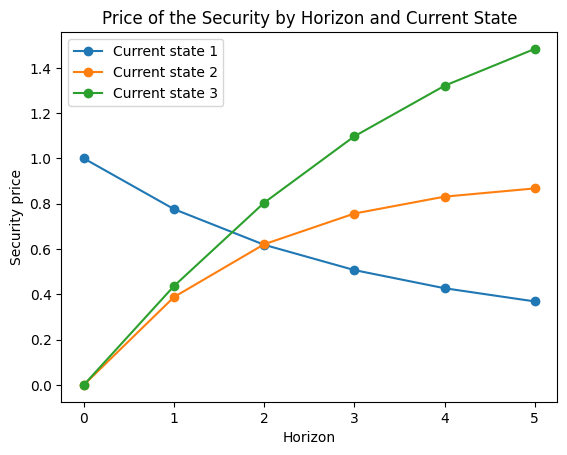

In [9]:
for i in range(n):
    plt.plot(range(T + 1), prices[:, i], marker="o", label=f"Current state {i+1}")

plt.xlabel("Horizon")
plt.ylabel("Security price")
plt.title("Price of the Security by Horizon and Current State")
plt.legend()
plt.show()


## 8. Special case: a $T$-period zero-coupon bond

A zero-coupon bond pays one unit in **every** state at date $T$. Therefore set

$$
r=\mathbf{1}.
$$

Its price vector is

$$
b^{(T)}=Q^T\mathbf{1}.
$$

The continuously compounded yield in current state $i$ is

$$
y_i^{(T)}
=
-\frac{1}{T}\log b_i^{(T)}.
$$


In [10]:
if T > 0:
    bond_payoff = np.ones(n)
    bond_price = np.linalg.matrix_power(Q, T) @ bond_payoff
    bond_yield = -np.log(bond_price) / T

    print(f"{T}-period bond prices:")
    print(bond_price)
    print()
    print(f"{T}-period continuously compounded yields:")
    print(bond_yield)
else:
    print("Set T >= 1 to compute a bond yield.")


5-period bond prices:
[0.468239 1.388896 2.583895]

5-period continuously compounded yields:
[ 0.151755 -0.065702 -0.18986 ]


## 9. Special case: an Arrow security

To price an Arrow security paying one unit in state $j$ at date $T$, set the payoff vector equal to the $j$th unit vector.

For example, a claim paying only in state 1 has

$$
r=
\begin{pmatrix}
1\\0\\\vdots\\0
\end{pmatrix}.
$$


In [11]:
arrow_state = 0  # Python counts states from 0

arrow_payoff = np.zeros(n)
arrow_payoff[arrow_state] = 1.0

arrow_price = np.linalg.matrix_power(Q, T) @ arrow_payoff

print(f"Price vector for a T={T} Arrow security paying in state {arrow_state+1}:")
print(arrow_price)


Price vector for a T=5 Arrow security paying in state 1:
[0.368594 0.867538 1.483315]


## 10. Economic summary

The entire calculation can be summarized as

$$
\boxed{
\text{preferences}
\rightarrow
\text{marginal utility}
\rightarrow
M
\rightarrow
Q
\rightarrow
Q^T r
}
$$

where

$$
M_{ij}
=
\beta\left(\frac{c_j}{c_i}\right)^{-\rho},
\qquad
Q=P\circ M.
$$

Three forces determine the price:

1. **Probability:** payoffs in more likely states receive more weight through $P$.
2. **Marginal utility:** payoffs in low-consumption states are especially valuable when $\rho>0$.
3. **Horizon:** longer-horizon claims are priced by repeated application of the same pricing operator $Q$.

The final formula is

$$
\boxed{
p^{(T)}=Q^T r.
}
$$
